In [791]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

pd.set_option('display.float_format',lambda x: '{:.2f}'.format(x))
np.set_printoptions(suppress=True)
warnings.filterwarnings('ignore')


In [792]:
df_customers = pd.read_csv('customers.csv')
df_loans = pd.read_csv('loans.csv')
df_bureau = pd.read_csv('bureau_data.csv')

In [793]:
df_customers.shape,df_loans.shape,df_bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [794]:
df_customers.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,West Bengal,700001
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,Karnataka,560001
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,Maharashtra,411001


In [795]:
df_loans.head()

,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,L00002,C00002,Home,Secured,4161000,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,L00003,C00003,Personal,Unsecured,2401000,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False
3,L00004,C00004,Personal,Unsecured,2345000,1747000,34940.00,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False
4,L00005,C00005,Auto,Secured,4647000,4520000,90400.00,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False


In [796]:
df_bureau.head()

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7
1,C00002,3,1,96,12,60,5,4
2,C00003,2,1,82,24,147,6,58
3,C00004,3,0,115,15,87,5,26
4,C00005,4,2,120,0,0,5,10


In [797]:
df = pd.merge(df_customers,df_loans,on='cust_id')
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,loan_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001,L00001,Auto,Secured,3004000,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001,L00002,Home,Secured,4161000,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,West Bengal,700001,L00003,Personal,Unsecured,2401000,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,Karnataka,560001,L00004,Personal,Unsecured,2345000,1747000,34940.00,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,Maharashtra,411001,L00005,Auto,Secured,4647000,4520000,90400.00,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False


In [798]:
df = pd.merge(df,df_bureau)

In [799]:
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,loan_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001,L00001,Auto,Secured,3004000,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001,L00002,Home,Secured,4161000,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,West Bengal,700001,L00003,Personal,Unsecured,2401000,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,Karnataka,560001,L00004,Personal,Unsecured,2345000,1747000,34940.00,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False,3,0,115,15,87,5,26
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,Maharashtra,411001,L00005,Auto,Secured,4647000,4520000,90400.00,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False,4,2,120,0,0,5,10


In [800]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      50000 non-null  object 
 1   age                          50000 non-null  int64  
 2   gender                       50000 non-null  object 
 3   marital_status               50000 non-null  object 
 4   employment_status            50000 non-null  object 
 5   income                       50000 non-null  int64  
 6   number_of_dependants         50000 non-null  int64  
 7   residence_type               49938 non-null  object 
 8   years_at_current_address     50000 non-null  int64  
 9   city                         50000 non-null  object 
 10  state                        50000 non-null  object 
 11  zipcode                      50000 non-null  int64  
 12  loan_id                      50000 non-null  object 
 13  loan_purpose    

In [801]:
df.default = df.default.astype(int)

In [802]:
df.default.info()

<class 'pandas.core.series.Series'>
RangeIndex: 50000 entries, 0 to 49999
Series name: default
Non-Null Count  Dtype
--------------  -----
50000 non-null  int64
dtypes: int64(1)
memory usage: 390.8 KB


In [803]:
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,loan_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001,L00001,Auto,Secured,3004000,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,0,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001,L00002,Home,Secured,4161000,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,0,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,West Bengal,700001,L00003,Personal,Unsecured,2401000,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,0,2,1,82,24,147,6,58
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,Karnataka,560001,L00004,Personal,Unsecured,2345000,1747000,34940.00,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,0,3,0,115,15,87,5,26
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,Maharashtra,411001,L00005,Auto,Secured,4647000,4520000,90400.00,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,0,4,2,120,0,0,5,10


In [804]:
X=df.drop(columns=['default'])
y=df['default']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.25,random_state=42)
df_train = pd.concat([X_train,y_train],axis='columns')
df_test = pd.concat([X_test,y_test],axis='columns')

In [805]:
df_test.shape

(12500, 33)

In [806]:
df_train.isna().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 48
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd     

In [807]:
df_train.residence_type.unique()

array(['Owned', 'Mortgage', 'Rented', nan], dtype=object)

In [808]:
df_train.residence_type = df_train.residence_type.fillna(df_train.residence_type.mode()[0])


In [809]:
df_train.residence_type.unique()

array(['Owned', 'Mortgage', 'Rented'], dtype=object)

In [810]:
df_test.residence_type = df_test.residence_type.fillna(df_train.residence_type.mode()[0])

In [811]:
df_test.residence_type.unique()

array(['Owned', 'Rented', 'Mortgage'], dtype=object)

In [812]:
df_train.duplicated().sum()

np.int64(0)

In [813]:
df_train.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default'],
      dtype='object')

In [814]:
columns_continuous =['age','income','number_of_dependants',
                    'years_at_current_address','zipcode','sanction_amount',
                    'loan_amount','gst','net_disbursement','loan_tenure_months','processing_fee',
                    'principal_outstanding','bank_balance_at_application','number_of_open_accounts',
                    'number_of_closed_accounts','total_loan_months','delinquent_months',
                    'total_dpd','enquiry_count','credit_utilization_ratio',
]
columns_categorical = ['gender','marital_status','employment_status',
                       'residence_type','state','zipcode',
                       'city','loan_purpose','loan_type','default']


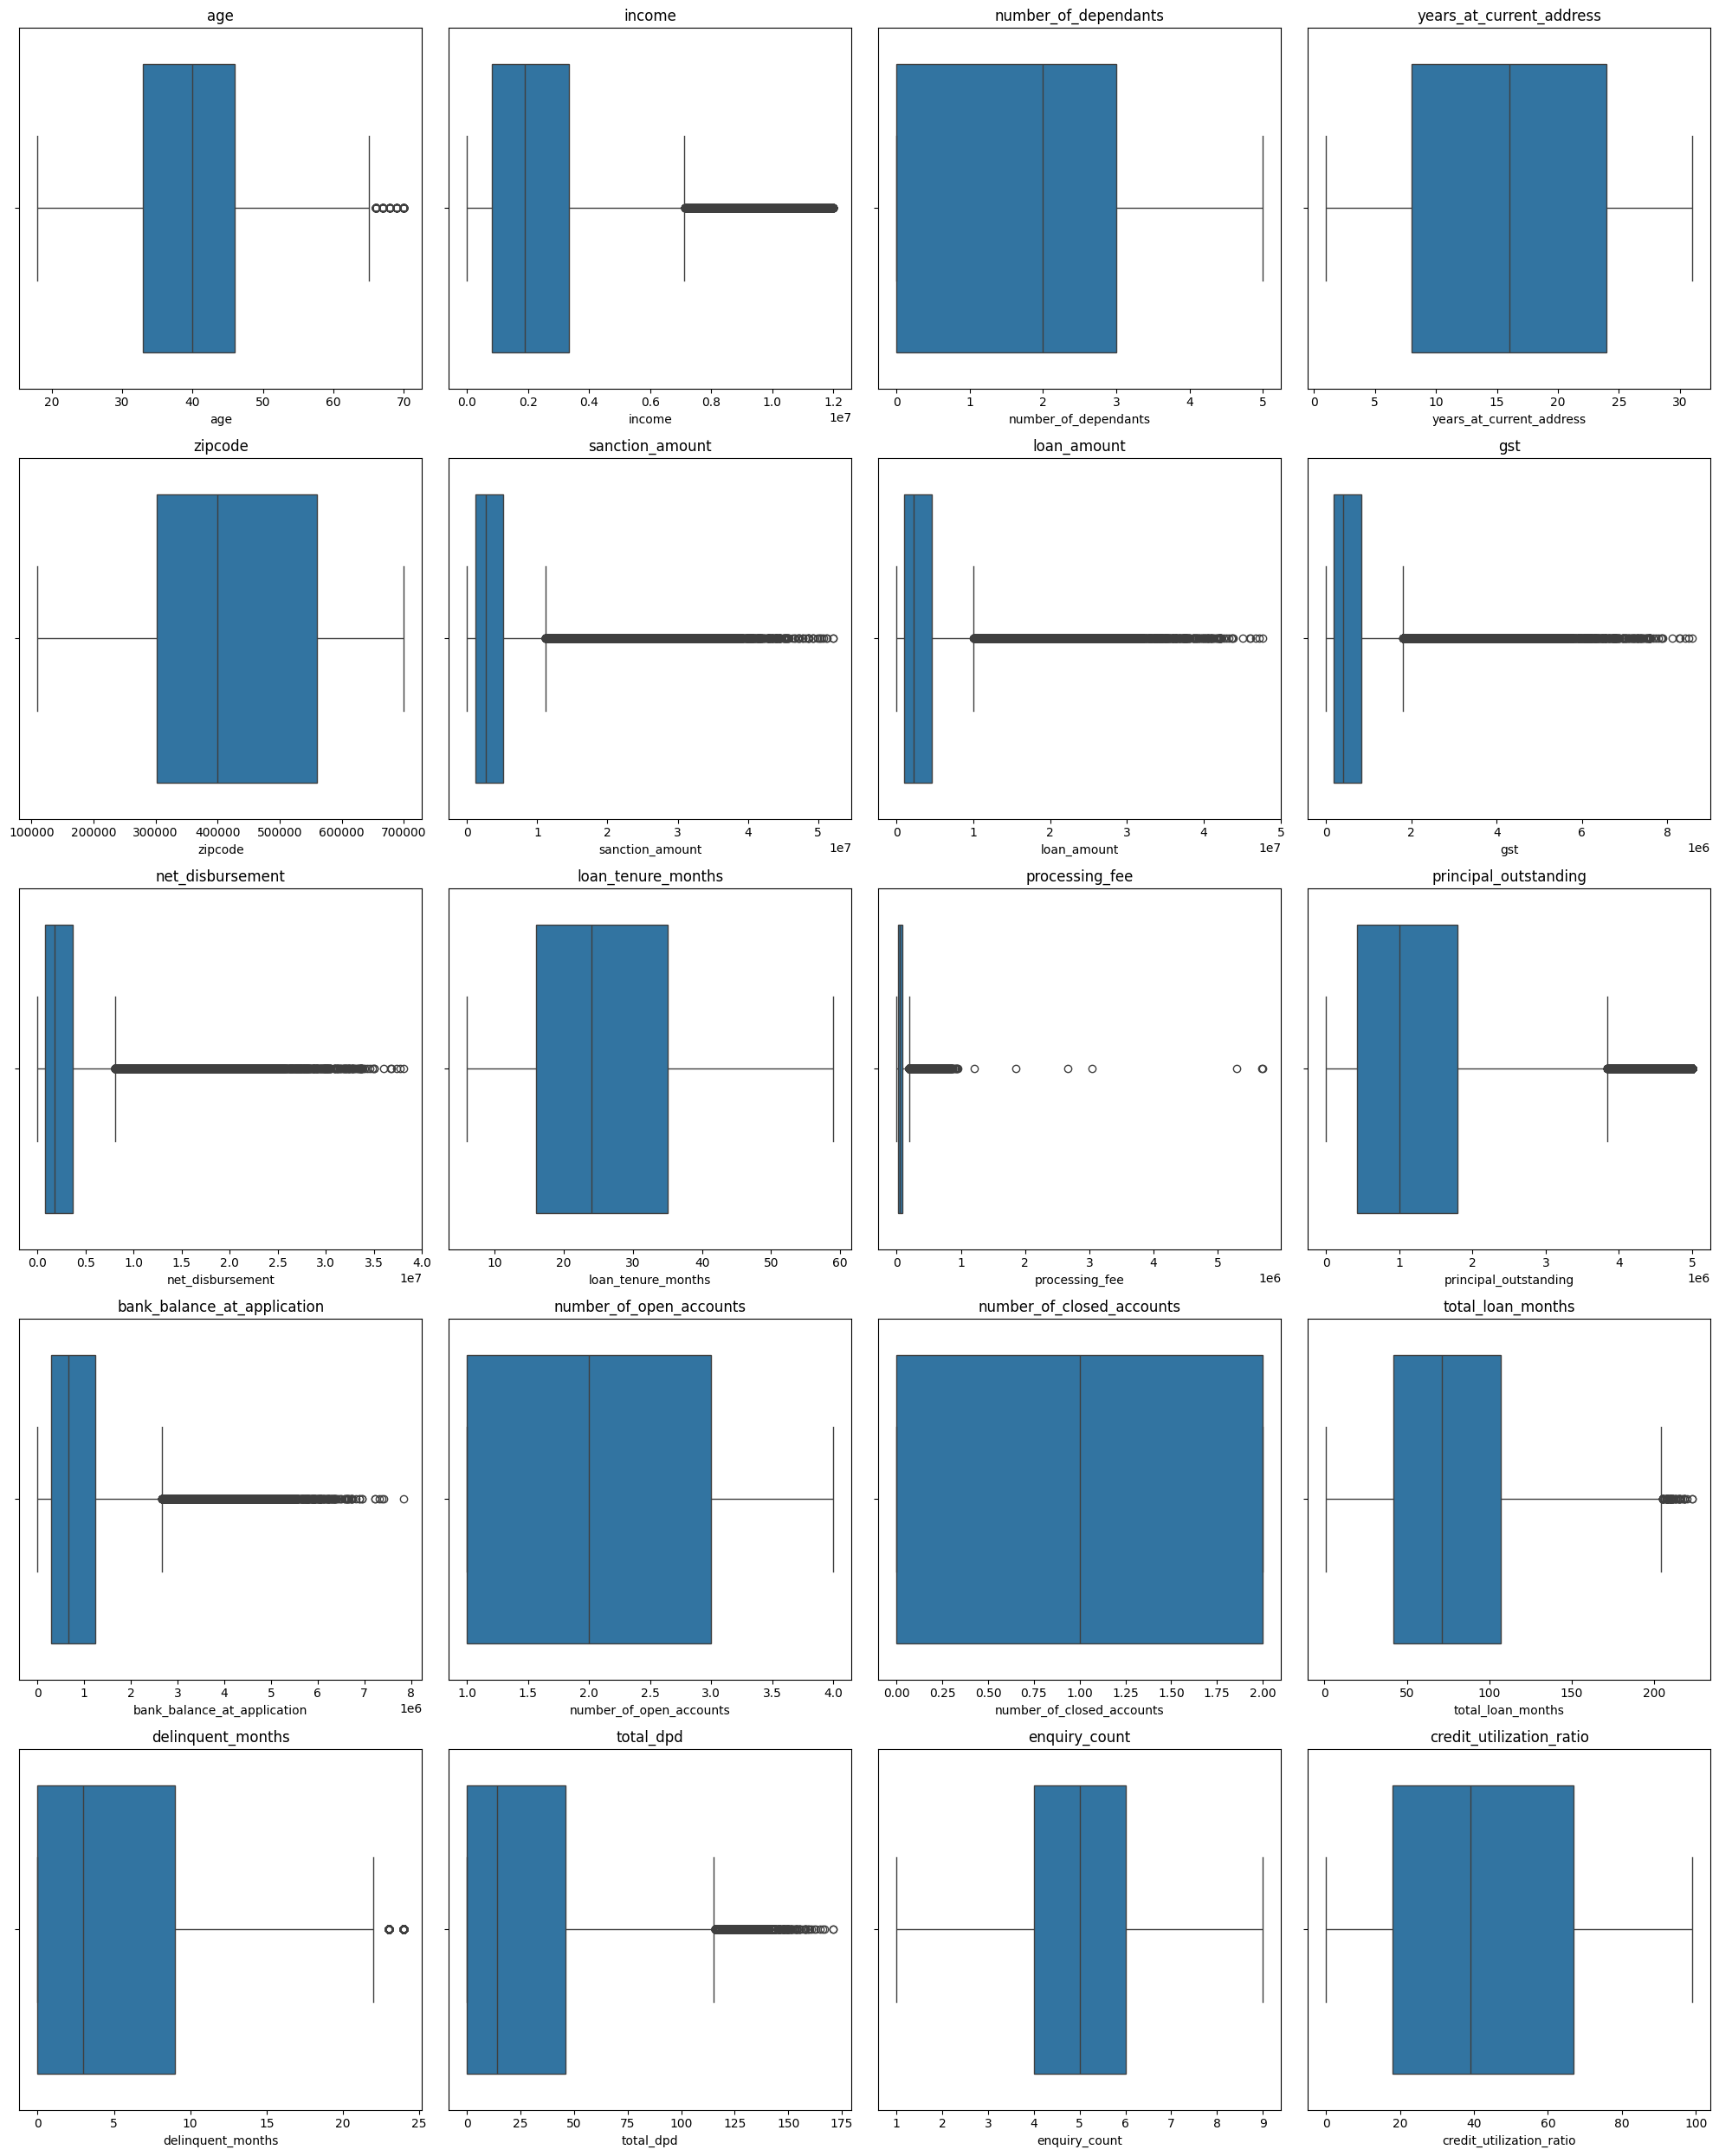

In [815]:
num_plots = len(columns_continuous)
num_cols = 4
num_rows = (num_plots + num_cols -1) // num_cols

fig,axes = plt.subplots(num_rows,num_cols,figsize=(5*num_cols,5*num_rows))
axes = axes.flatten()

for ax,(col) in zip(axes,columns_continuous):
    sns.boxplot(x=df_train[col],ax=ax)
    ax.set_title(col)

for i in range(len(columns_continuous),num_rows*num_cols):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

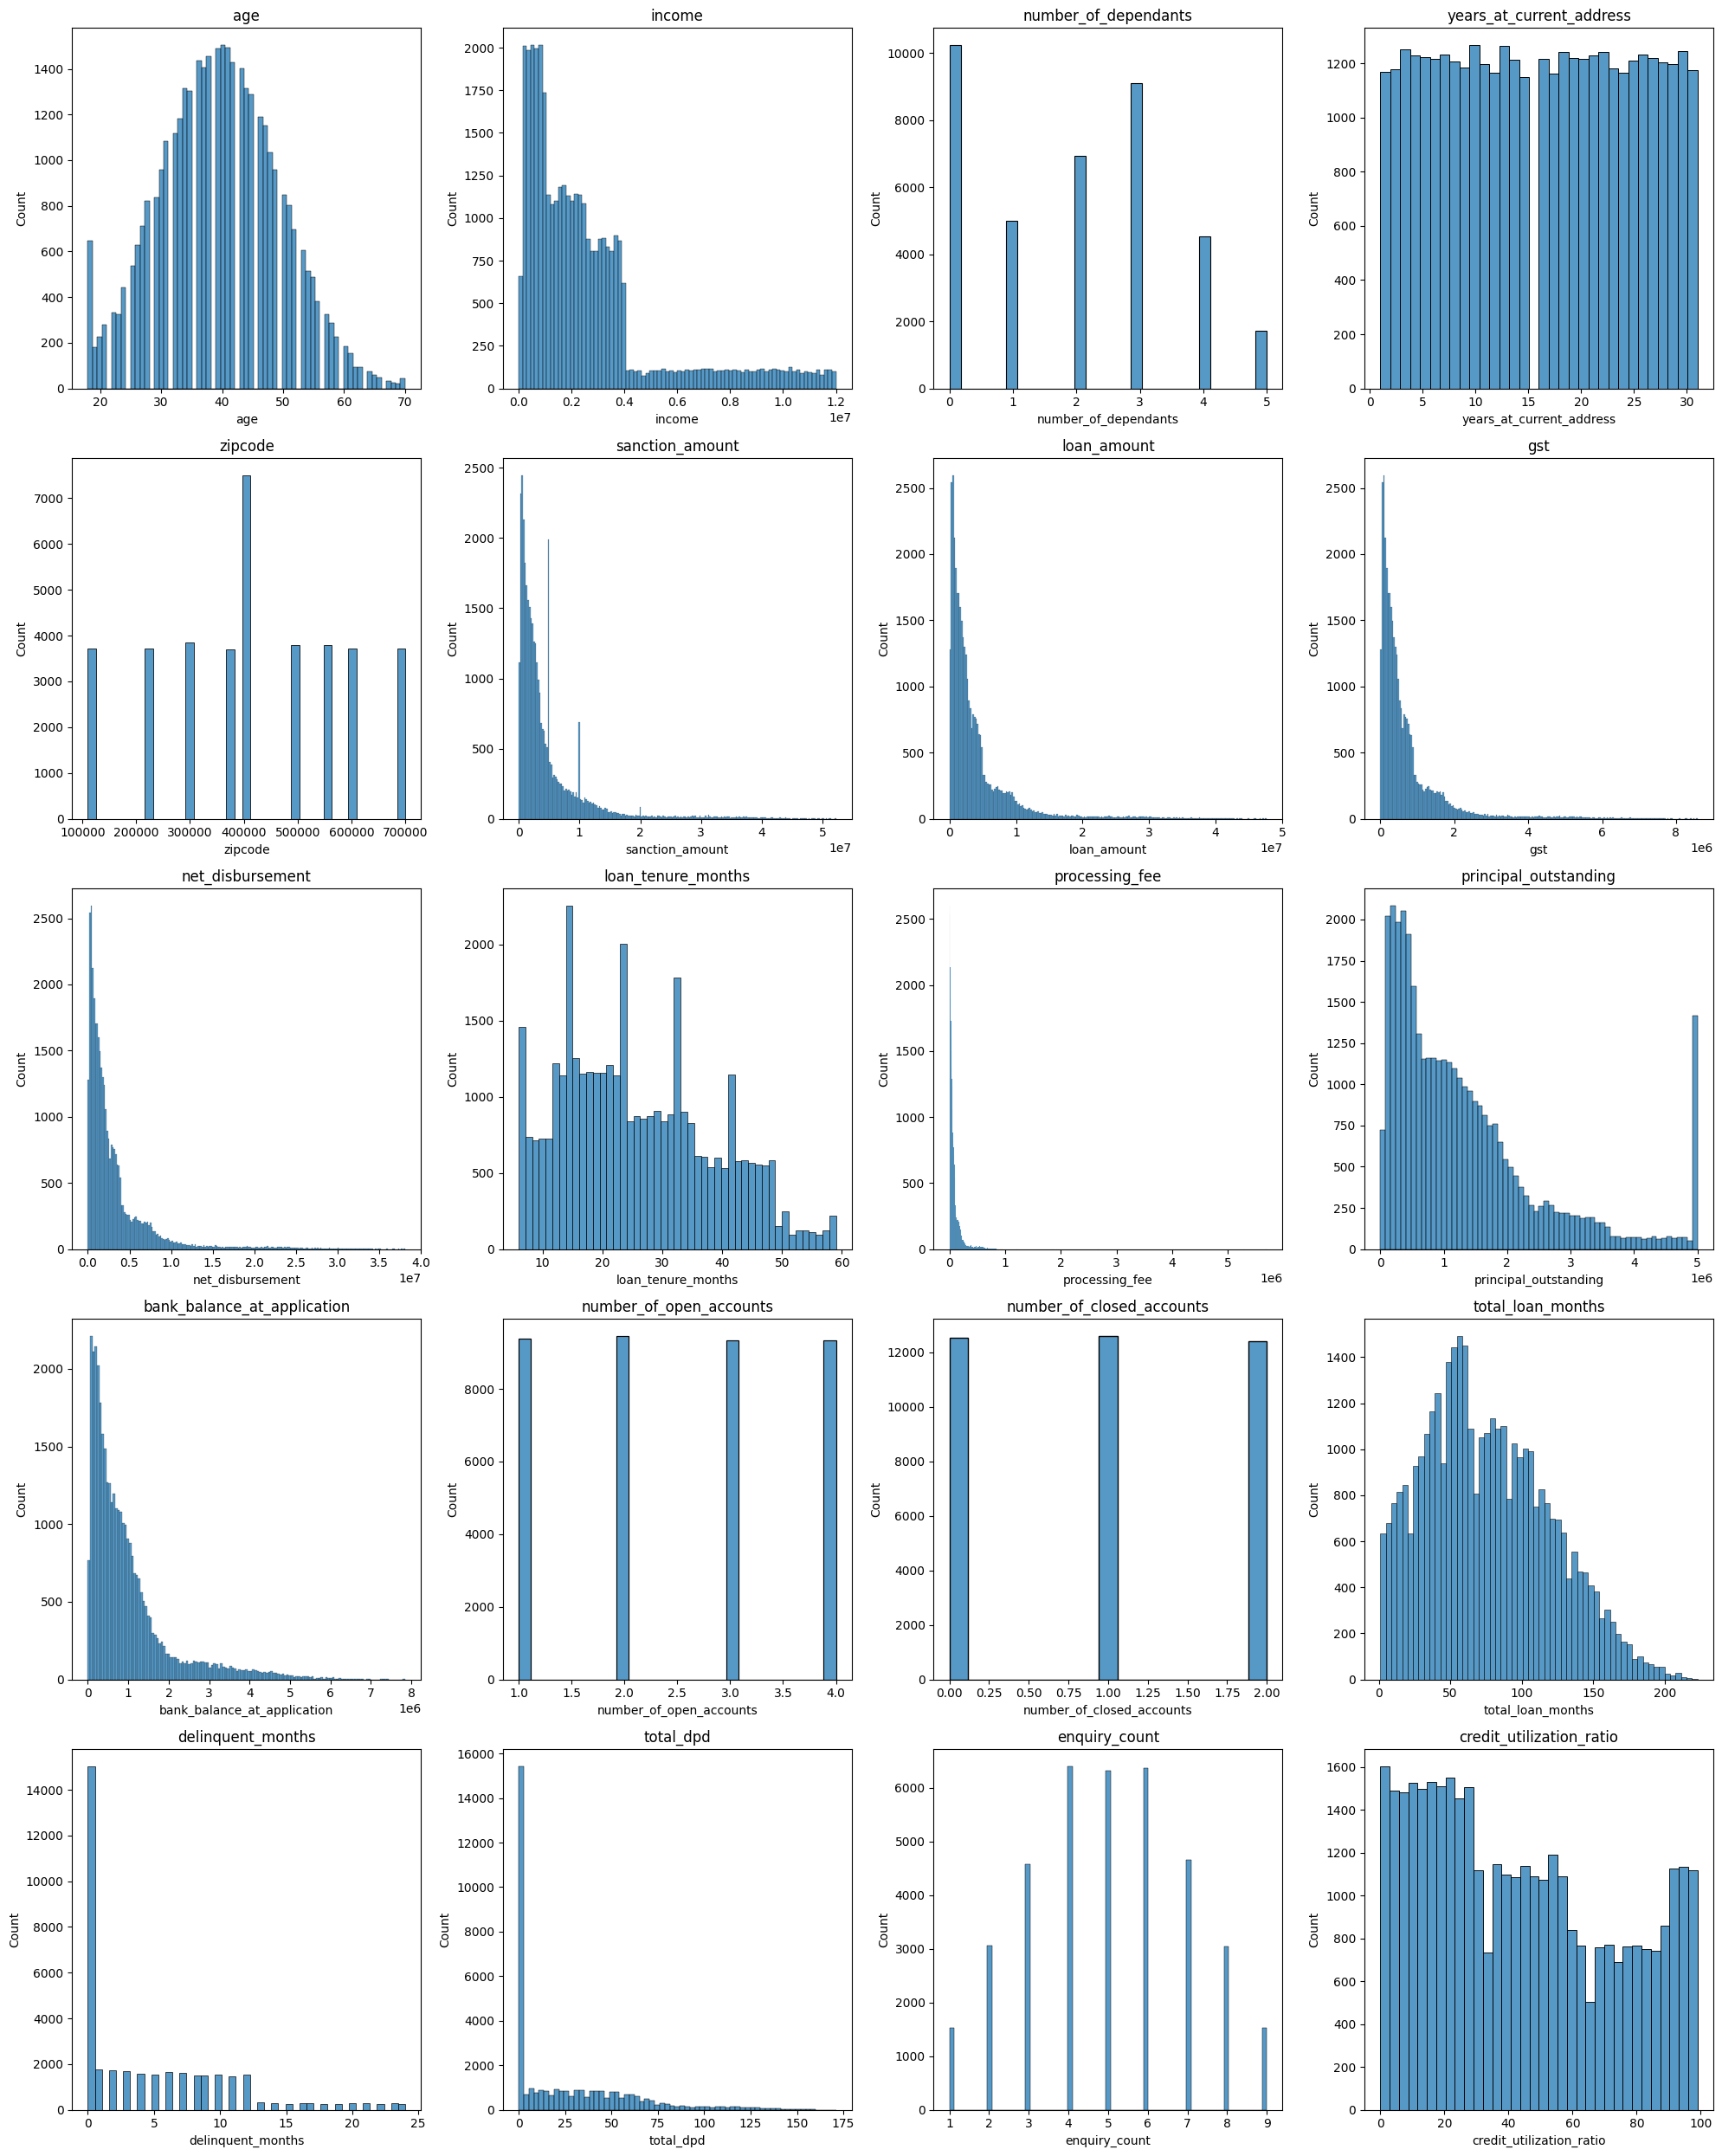

In [816]:


fig,axes = plt.subplots(num_rows,num_cols,figsize=(5*num_cols,5*num_rows))
axes = axes.flatten()

for ax,(col) in zip(axes,columns_continuous):
    sns.histplot(x=df_train[col],ax=ax)
    ax.set_title(col)

for i in range(len(columns_continuous),num_rows*num_cols):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [817]:
df_train.processing_fee.describe()

count     37500.00
mean      80724.11
std      120830.65
min           0.00
25%       19180.00
50%       44700.00
75%       92000.00
max     5698029.90
Name: processing_fee, dtype: float64

In [818]:
df_train[df_train.processing_fee==df_train.processing_fee.max()][['loan_amount','processing_fee']]

,loan_amount,processing_fee
12294,4639000,5698029.90


In [819]:
df_train[(df_train.processing_fee/df_train.loan_amount)>0.03][['loan_amount','processing_fee']]

,loan_amount,processing_fee
23981,2234000,2669791.02
9898,3626000,5293543.52
47089,1738000,1858964.77
33705,3812000,5678020.86
12294,4639000,5698029.90
28174,966000,1214492.67
29305,2616000,3036378.01


In [820]:
df_train_1 = df_train[(df_train.processing_fee/df_train.loan_amount)<0.03].copy()

In [821]:
df_train_1[(df_train_1.processing_fee/df_train_1.loan_amount)>0.03][['loan_amount','processing_fee']]

,loan_amount,processing_fee


In [822]:
columns_categorical

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'state',
 'zipcode',
 'city',
 'loan_purpose',
 'loan_type',
 'default']

In [823]:
for col in columns_categorical:
    print(col,'=',df_train_1[col].unique())

gender = ['F' 'M']
marital_status = ['Single' 'Married']
employment_status = ['Salaried' 'Self-Employed']
residence_type = ['Owned' 'Mortgage' 'Rented']
state = ['Gujarat' 'Delhi' 'Uttar Pradesh' 'Karnataka' 'Rajasthan' 'Telangana'
 'West Bengal' 'Maharashtra' 'Tamil Nadu']
zipcode = [380001 110001 226001 560001 302001 500001 700001 411001 600001 400001]
city = ['Ahmedabad' 'Delhi' 'Lucknow' 'Bangalore' 'Jaipur' 'Hyderabad' 'Kolkata'
 'Pune' 'Chennai' 'Mumbai']
loan_purpose = ['Home' 'Auto' 'Personal' 'Education' 'Personaal']
loan_type = ['Secured' 'Unsecured']
default = [0 1]


In [824]:
df_train_1['loan_purpose'] = df_train_1['loan_purpose'].replace('Personaal','Personal')


In [881]:
X_test['loan_purpose'] = X_test['loan_purpose'].replace('Personaal','Personal')


<h1>Exploratory Data Analysis</h1>

In [826]:
columns_continuous

['age',
 'income',
 'number_of_dependants',
 'years_at_current_address',
 'zipcode',
 'sanction_amount',
 'loan_amount',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'processing_fee',
 'principal_outstanding',
 'bank_balance_at_application',
 'number_of_open_accounts',
 'number_of_closed_accounts',
 'total_loan_months',
 'delinquent_months',
 'total_dpd',
 'enquiry_count',
 'credit_utilization_ratio']

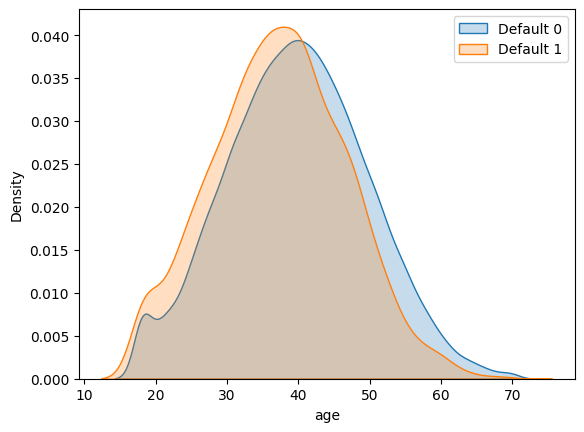

In [827]:
sns.kdeplot(df_train[df_train.default==0]['age'],fill=True,label='Default 0')
sns.kdeplot(df_train[df_train.default==1]['age'],fill=True,label='Default 1')
plt.legend()
plt.show()

Insight
    1, Orange graph is little bit shifted

In [828]:
df_train_1

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,loan_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
27434,C27435,45,F,Single,Salaried,1131000,0,Owned,5,Ahmedabad,Gujarat,380001,L27435,Home,Secured,3458000,3276000,65520.00,589680,2620800,24,905176,566117,2022-04-21,2022-05-21,4,2,90,6,33,8,59,0
13400,C13401,29,M,Single,Salaried,2343000,0,Owned,25,Delhi,Delhi,110001,L13401,Auto,Secured,3103000,2540000,50800.00,457200,2032000,33,1008916,951329,2020-11-24,2020-12-11,3,1,119,4,17,4,92,0
883,C00884,50,F,Single,Self-Employed,2891000,0,Mortgage,29,Lucknow,Uttar Pradesh,226001,L00884,Personal,Unsecured,2288000,1920000,38400.00,345600,1536000,19,1382399,771873,2019-08-25,2019-09-19,2,1,83,14,78,4,83,0
7303,C07304,43,F,Single,Self-Employed,272000,1,Owned,27,Bangalore,Karnataka,560001,L07304,Auto,Secured,307000,298000,5960.00,53640,238400,21,170015,117343,2020-04-16,2020-05-05,1,1,37,0,0,5,34,0
45124,C45125,31,F,Single,Salaried,141000,0,Owned,27,Jaipur,Rajasthan,302001,L45125,Education,Secured,283000,260000,5200.00,46800,208000,45,72025,67719,2024-01-26,2024-02-17,2,0,62,6,28,5,19,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,C11285,33,F,Single,Salaried,3506000,0,Rented,31,Hyderabad,Telangana,500001,L11285,Auto,Secured,5201000,4760000,95200.00,856800,3808000,19,2397863,1408084,2020-09-08,2020-09-17,4,1,129,23,126,7,93,1
44732,C44733,33,F,Single,Salaried,3889000,0,Owned,26,Delhi,Delhi,110001,L44733,Auto,Secured,5400000,5302000,106040.00,954360,4241600,12,1676958,1215502,2024-01-12,2024-01-21,3,0,80,0,0,3,23,0
38158,C38159,35,M,Married,Self-Employed,2420000,3,Rented,5,Kolkata,West Bengal,700001,L38159,Home,Secured,8212000,6570000,131400.00,1182600,5256000,48,1497625,993374,2023-05-17,2023-06-14,1,2,8,0,0,2,53,0
860,C00861,42,F,Married,Salaried,2133000,4,Owned,6,Mumbai,Maharashtra,400001,L00861,Education,Secured,3755000,3194000,63880.00,574920,2555200,22,1316297,672134,2019-08-25,2019-09-12,3,1,130,5,24,7,17,0


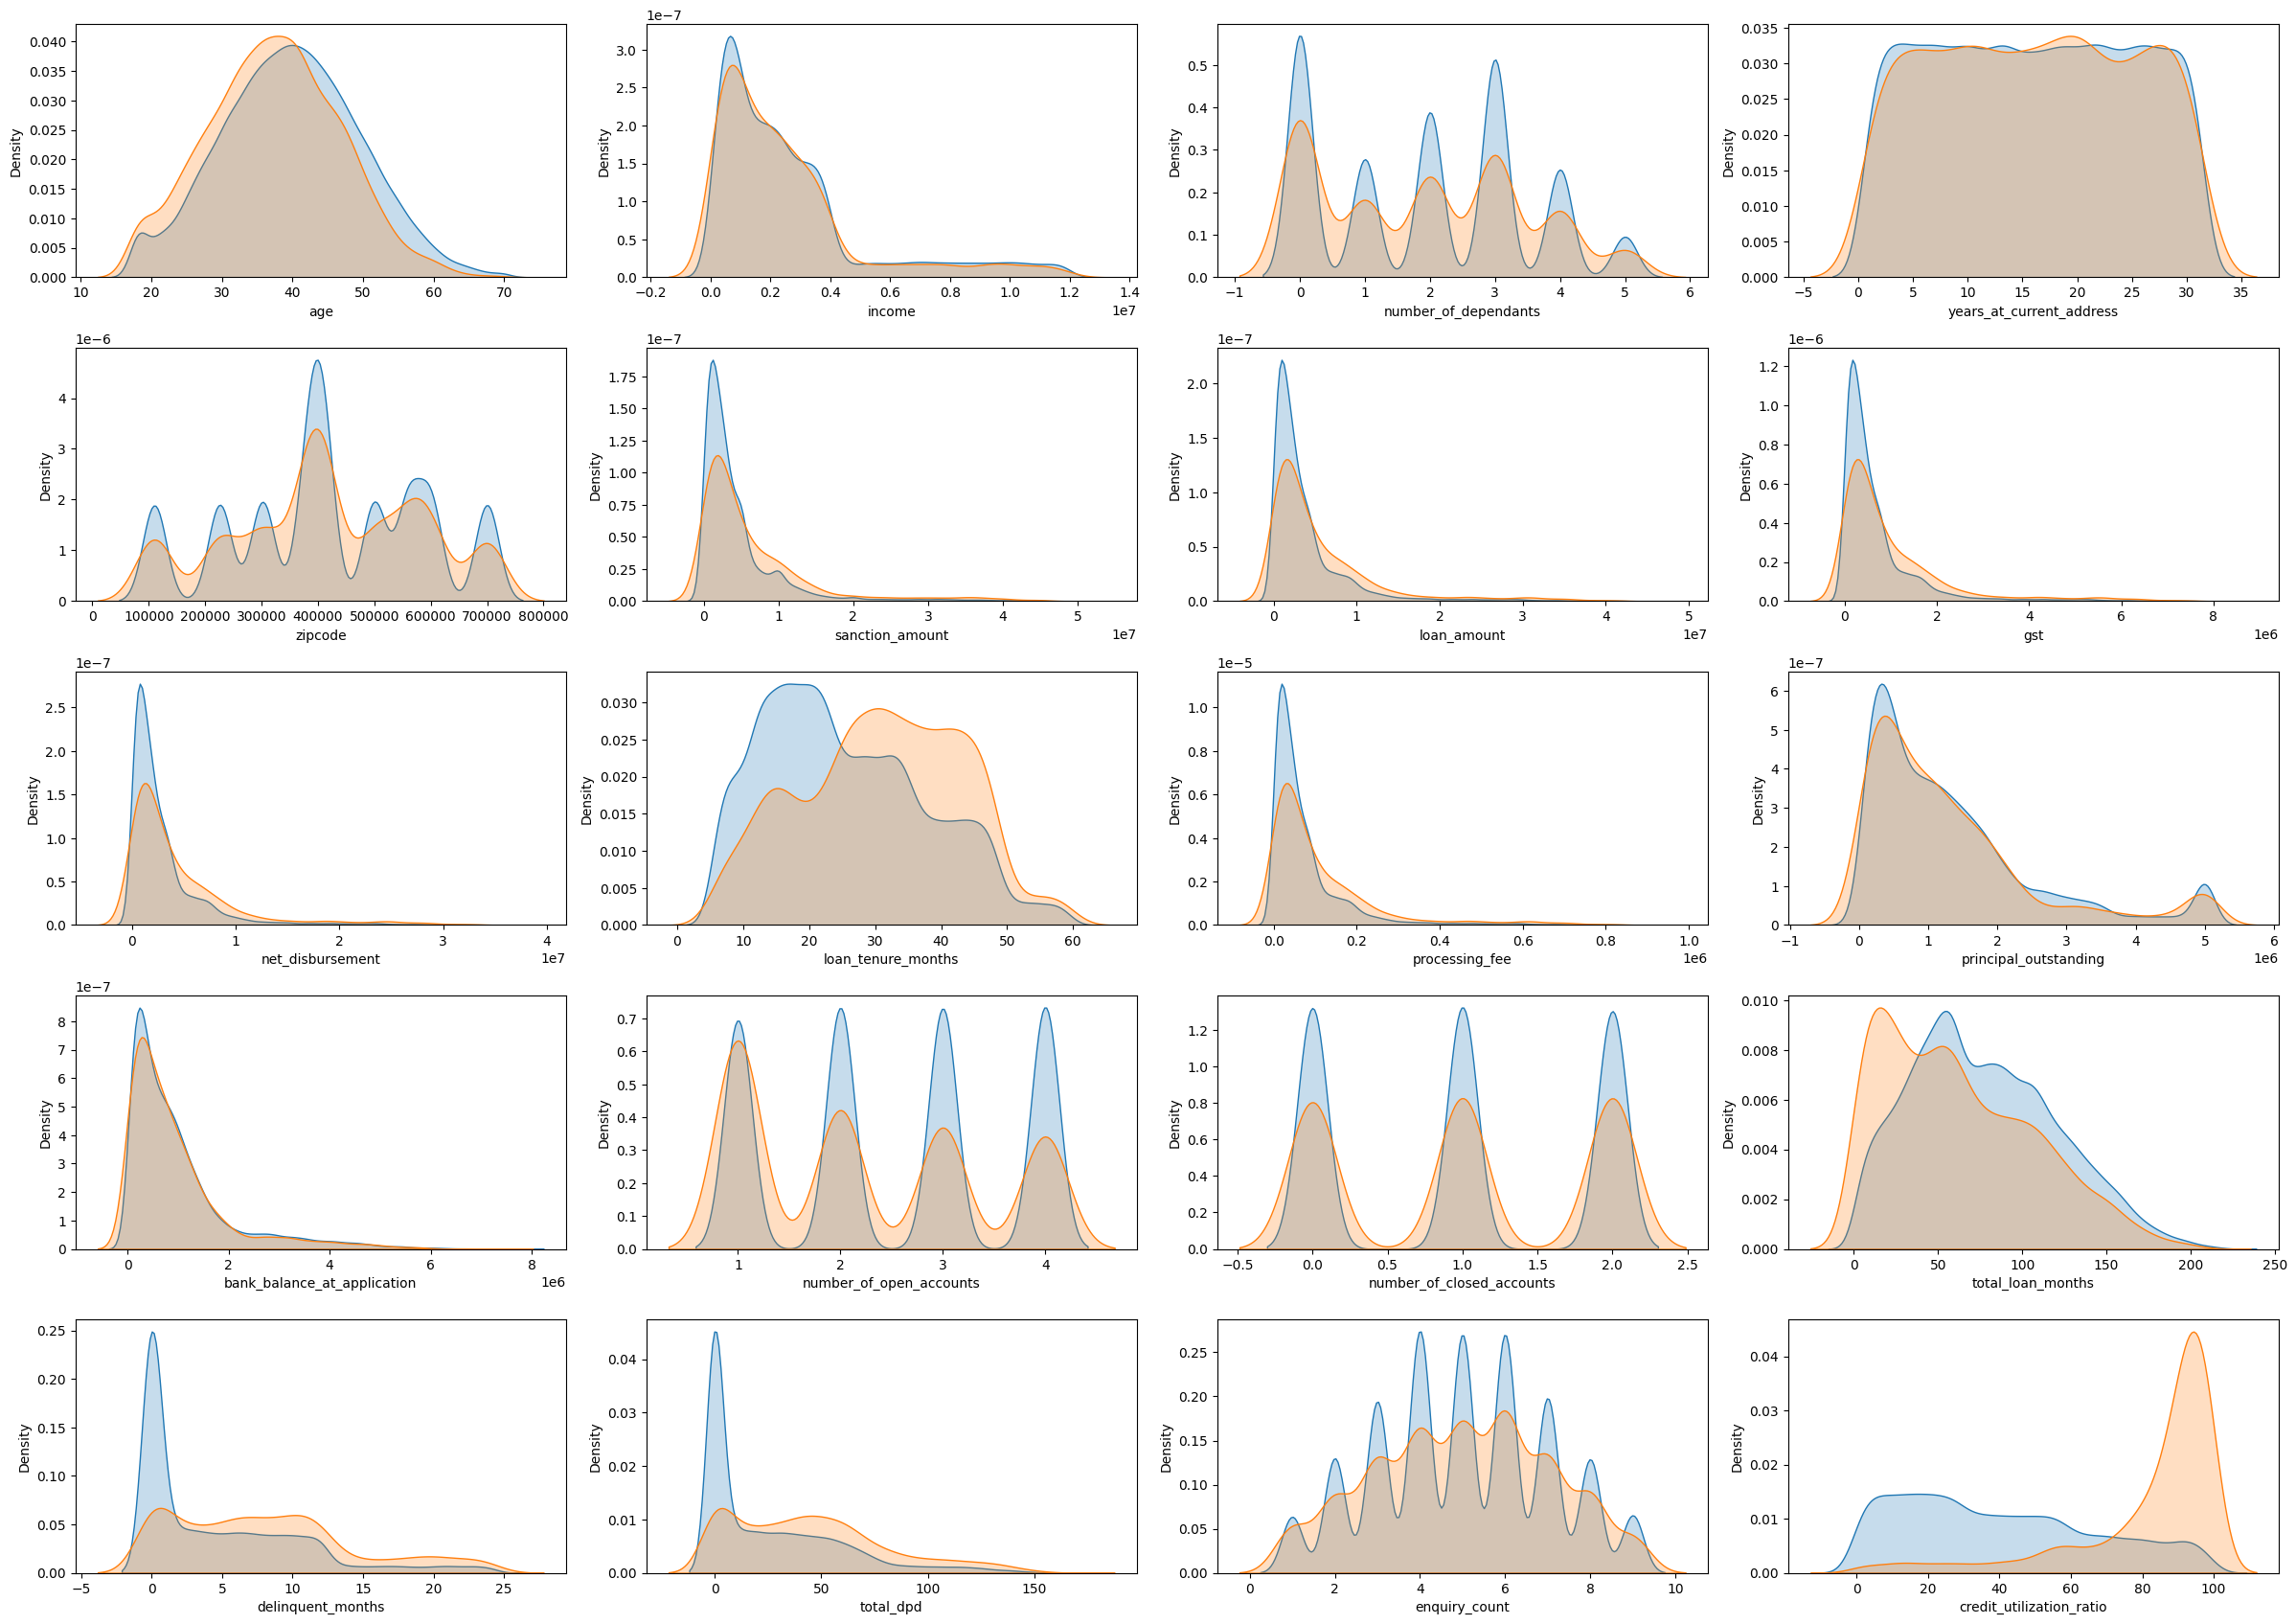

In [829]:
plt.figure(figsize=(24,20))

for i,col in enumerate(columns_continuous):
    plt.subplot(6,4,i+1)
    sns.kdeplot(df_train_1[col][df_train_1.default==0],fill=True,label='Default 0')
    sns.kdeplot(df_train_1[col][df_train_1.default==1],fill=True,label='Default 1')
    plt.xlabel(col)
plt.tight_layout()
plt.show()

Insight
1. In columns: loan_

<h1>Feature Engineering</h1>

In [830]:
df_train_1['loan_to_income'] = round(df_train_1['loan_amount']/df_train_1['income'],2)
df_test['loan_to_income'] = round(df_test['loan_amount']/df_test['income'],2)
df_train_1['loan_to_income'].describe()

count   37487.00
mean        1.55
std         0.97
min         0.30
25%         0.77
50%         1.16
75%         2.45
max         4.57
Name: loan_to_income, dtype: float64

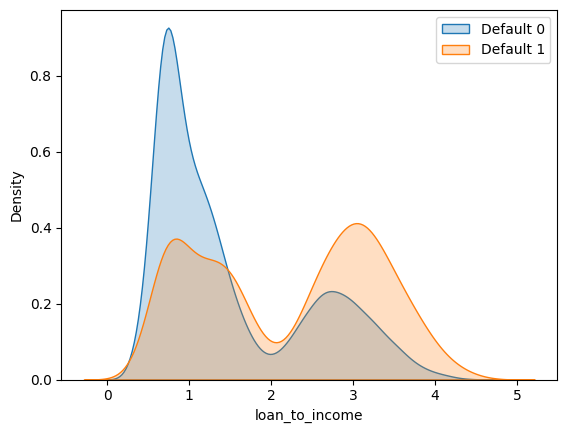

In [831]:
sns.kdeplot(df_train_1[df_train_1.default==0]['loan_to_income'],fill=True,label='Default 0')
sns.kdeplot(df_train_1[df_train_1.default==1]['loan_to_income'],fill=True,label='Default 1')
plt.legend()
plt.show()

In [832]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income'],
      dtype='object')

In [833]:
df_train_1[['delinquent_months','total_loan_months']]

,delinquent_months,total_loan_months
27434,6,90
13400,4,119
883,14,83
7303,0,37
45124,6,62
...,...,...
11284,23,129
44732,0,80
38158,0,8
860,5,130


In [834]:
df_train_1['delinquent_ratio'] =( df_train_1['delinquent_months']*100/df_train_1['total_loan_months']).round(1)
df_test['delinquent_ratio'] =( df_test['delinquent_months']*100/df_test['total_loan_months']).round(1)

In [835]:
df_train_1['delinquent_ratio']

27434    6.70
13400    3.40
883     16.90
7303     0.00
45124    9.70
         ... 
11284   17.80
44732    0.00
38158    0.00
860      3.80
15795    4.90
Name: delinquent_ratio, Length: 37487, dtype: float64

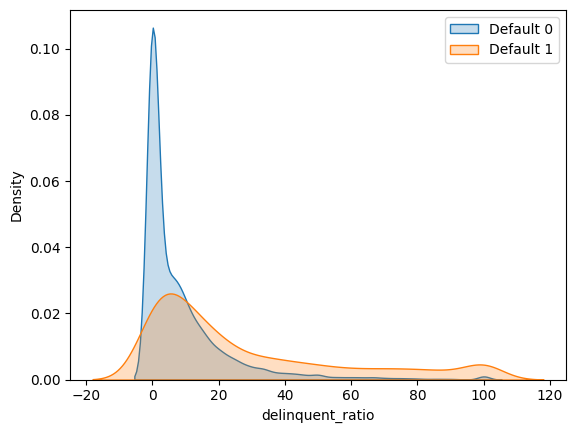

In [836]:
sns.kdeplot(df_train_1[df_train_1.default==0]['delinquent_ratio'],fill=True,label='Default 0')
sns.kdeplot(df_train_1[df_train_1.default==1]['delinquent_ratio'],fill=True,label='Default 1')
plt.legend()
plt.show()

In [837]:
df_train_1['avg_dpd_per_delinquency'] =np.where(
    df_train_1['delinquent_months'] !=0,
    (df_train_1['total_dpd']/df_train_1['delinquent_months']).round(1),
    0
    )

df_test['avg_dpd_per_delinquency'] =np.where(
    df_test['delinquent_months'] !=0,
    (df_test['total_dpd']/df_test['delinquent_months']).round(1),
    0
    )

df_train_1['avg_dpd_per_delinquency'].describe()

count   37487.00
mean        3.29
std         2.90
min         0.00
25%         0.00
50%         4.30
75%         5.80
max        10.00
Name: avg_dpd_per_delinquency, dtype: float64

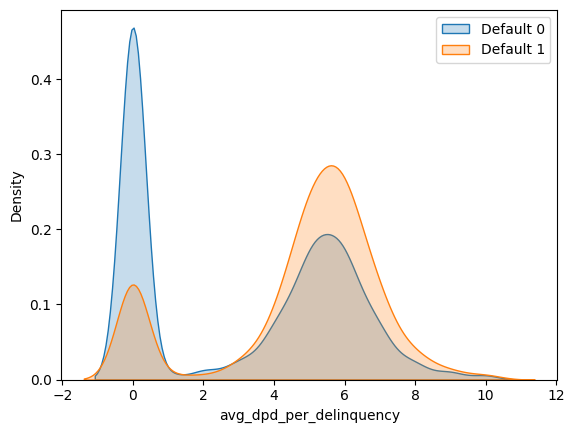

In [838]:
sns.kdeplot(df_train_1[df_train_1.default==0]['avg_dpd_per_delinquency'],fill=True,label='Default 0')
sns.kdeplot(df_train_1[df_train_1.default==1]['avg_dpd_per_delinquency'],fill=True,label='Default 1')
plt.legend()
plt.show()

## Feature Selection

In [839]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income', 'delinquent_ratio', 'avg_dpd_per_delinquency'],
      dtype='object')

In [840]:
df_train_2 = df_train_1.drop(columns=['cust_id','loan_id','disbursal_date','installment_start_dt','income','loan_amount','total_loan_months','delinquent_months','total_dpd'])
df_test = df_test.drop(columns=['cust_id','loan_id','disbursal_date','installment_start_dt','income','loan_amount','total_loan_months','delinquent_months','total_dpd'])

In [841]:
df_train_2.columns

Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income',
       'delinquent_ratio', 'avg_dpd_per_delinquency'],
      dtype='object')

In [842]:
df_train_2.select_dtypes(['int64','float64']).columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income',
       'delinquent_ratio', 'avg_dpd_per_delinquency'],
      dtype='object')

In [843]:
X_train=df_train_2.drop(columns=['default'])
y_train=df_train_2['default']

from sklearn.preprocessing import MinMaxScaler

cols_to_scale = X_train.select_dtypes(['int64','float64']).columns

scaler = MinMaxScaler()
X_train[cols_to_scale]=scaler.fit_transform(X_train[cols_to_scale])
X_train.describe()


,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency
count,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00,37487.00
mean,0.41,0.39,0.50,0.52,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.50,0.50,0.50,0.44,0.29,0.10,0.33
std,0.19,0.31,0.30,0.29,0.12,0.11,0.11,0.11,0.23,0.24,0.13,0.37,0.41,0.25,0.30,0.23,0.17,0.29
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,0.33,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.00,0.00,0.38,0.18,0.11,0.00,0.00
50%,0.42,0.40,0.50,0.49,0.05,0.05,0.05,0.05,0.34,0.19,0.08,0.33,0.50,0.50,0.39,0.20,0.04,0.43
75%,0.54,0.60,0.77,0.76,0.10,0.10,0.10,0.10,0.55,0.35,0.16,0.67,1.00,0.62,0.68,0.50,0.13,0.58
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [844]:
X_test=df_test.drop(columns=['default'])
y_test=df_test['default']
X_test[cols_to_scale] = scaler.fit_transform(X_test[cols_to_scale])
X_test.describe()


,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency
count,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12500.00,12498.00,12500.00,12500.00
mean,0.41,0.39,0.50,0.53,0.09,0.08,0.08,0.08,0.38,0.27,0.14,0.50,0.51,0.50,0.44,0.29,0.10,0.33
std,0.19,0.31,0.30,0.29,0.13,0.11,0.11,0.11,0.24,0.24,0.15,0.37,0.41,0.26,0.30,0.23,0.17,0.29
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,0.33,0.02,0.02,0.02,0.02,0.19,0.09,0.04,0.00,0.00,0.38,0.18,0.11,0.00,0.00
50%,0.42,0.40,0.50,0.51,0.05,0.05,0.05,0.05,0.36,0.20,0.10,0.67,0.50,0.50,0.39,0.20,0.04,0.43
75%,0.54,0.60,0.77,0.76,0.11,0.10,0.10,0.10,0.55,0.36,0.18,1.00,1.00,0.75,0.68,0.50,0.13,0.58
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [845]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df=pd.DataFrame()
    vif_df['Column'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values,i) for i in range(data.shape[1])]
    return vif_df

In [846]:
calculate_vif(X_train[cols_to_scale])

,Column,VIF
0,age,5.72
1,number_of_dependants,2.73
2,years_at_current_address,3.42
3,zipcode,3.79
4,sanction_amount,102.15
5,processing_fee,inf
6,gst,inf
7,net_disbursement,inf
8,loan_tenure_months,6.14
9,principal_outstanding,16.28


In [847]:
feature_to_drop = ['sanction_amount','principal_outstanding','processing_fee','gst','net_disbursement']
x_train_1 = X_train.drop(columns=feature_to_drop)

In [848]:
numeric_columns = x_train_1.select_dtypes(['int64','float64']).columns
vif_df = calculate_vif(x_train_1[numeric_columns])
vif_df

,Column,VIF
0,age,5.45
1,number_of_dependants,2.73
2,years_at_current_address,3.41
3,zipcode,3.77
4,loan_tenure_months,5.98
5,bank_balance_at_application,1.80
6,number_of_open_accounts,4.32
7,number_of_closed_accounts,2.35
8,enquiry_count,6.37
9,credit_utilization_ratio,2.92


In [849]:
selected_numeric_feature_vif = vif_df.Column.values
selected_numeric_feature_vif

array(['age', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'enquiry_count', 'credit_utilization_ratio', 'loan_to_income',
       'delinquent_ratio', 'avg_dpd_per_delinquency'], dtype=object)

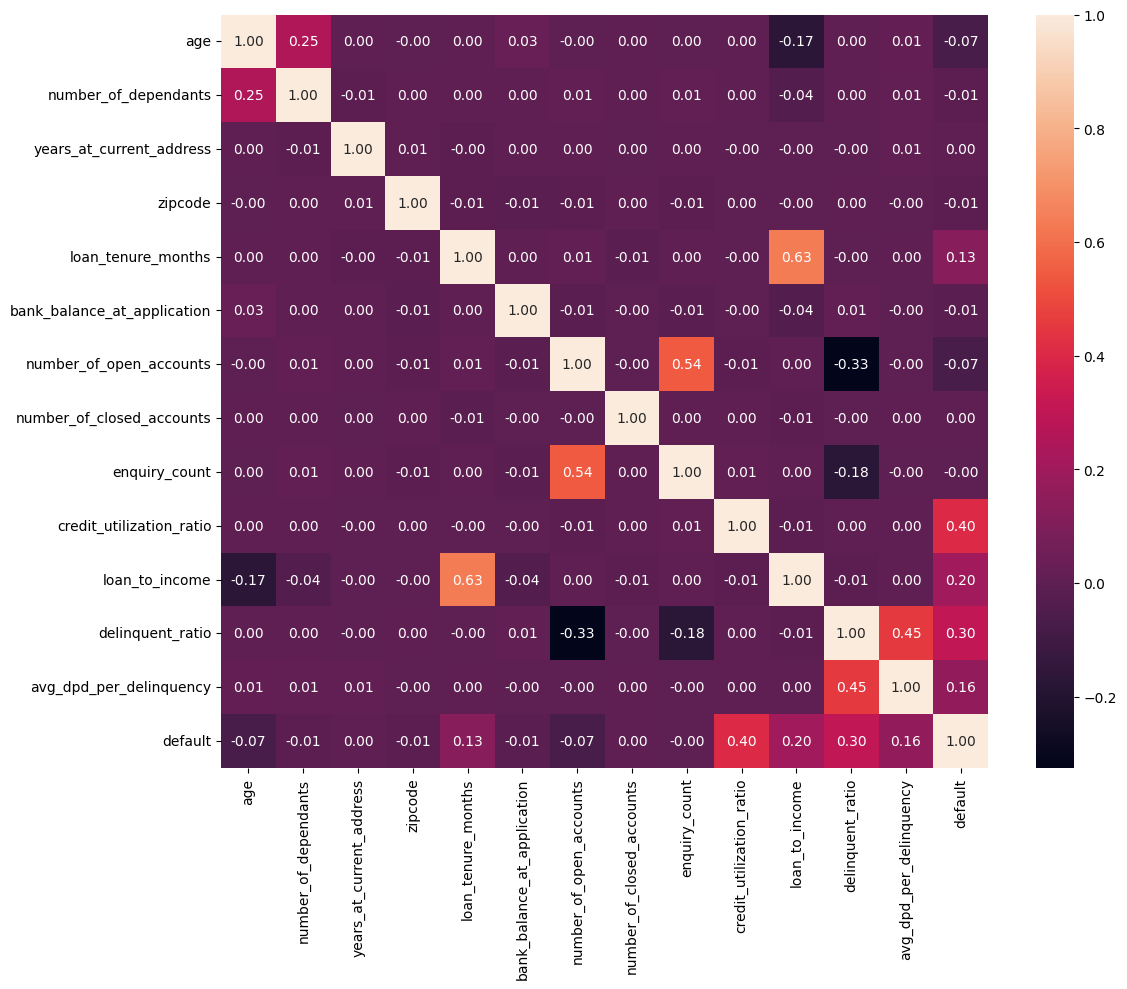

In [850]:
plt.figure(figsize=(12,10))
cm=df_train_2[numeric_columns.append(pd.Index(['default']))].corr()
sns.heatmap(cm,annot=True,fmt='0.2f')
plt.tight_layout()
plt.show()

In [851]:
columns_categorical

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'state',
 'zipcode',
 'city',
 'loan_purpose',
 'loan_type',
 'default']

In [852]:
def calculate_woe_iv(df,feature,target):
    grouped = df.groupby(feature)[target].agg(['count','sum'])
    grouped =grouped.rename(columns={
        'count':'total',
        'sum':'good'
    })
    grouped['bad'] = grouped['total'] - grouped['good']
    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()

    grouped['good_pct'] = grouped['good'] / total_good
    grouped['bad_pct'] = grouped['bad'] / total_bad

    grouped['woe'] = np.log(grouped['good_pct']/ grouped['bad_pct'])
    grouped['iv'] =( grouped['good_pct']- grouped['bad_pct'] )* grouped['woe']
    grouped['woe']=    grouped['woe'].replace([np.inf,-np.inf],0)
    grouped['iv']=    grouped['iv'].replace([np.inf,-np.inf],0)
    total_iv = grouped['iv'].sum()
    return grouped, total_iv

grouped, total_iv = calculate_woe_iv(df=pd.concat([x_train_1,y_train],axis=1),feature='loan_purpose',target='default')
grouped

,total,good,bad,good_pct,bad_pct,woe,iv
loan_purpose,,,,,,,
Auto,7437,314,7123,0.10,0.21,-0.75,0.08
Education,5626,546,5080,0.17,0.15,0.14,0.00
Home,11271,1744,9527,0.55,0.28,0.68,0.18
Personal,13153,585,12568,0.18,0.37,-0.69,0.13


In [853]:
total_iv

np.float64(0.39377543144164784)

In [854]:
iv_values = {}
for feature in x_train_1.columns:
    if x_train_1[feature].dtype == 'object':
        _,iv=calculate_woe_iv(pd.concat([x_train_1,y_train],axis=1),feature,'default')
    else:
        x_bin = pd.cut(x_train_1[feature],bins=10,labels=False)
        _,iv=calculate_woe_iv(pd.concat([x_bin,y_train],axis=1),feature,'default')
    iv_values[feature] = iv



iv_values


{'age': np.float64(0.07592687127752061),
 'gender': np.float64(0.000482276463421216),
 'marital_status': np.float64(0.002196681370832318),
 'employment_status': np.float64(0.002447818101774487),
 'number_of_dependants': np.float64(0.00364589452118596),
 'residence_type': np.float64(0.2594019617563985),
 'years_at_current_address': np.float64(0.001042536380353028),
 'city': np.float64(0.000817870465334103),
 'state': np.float64(0.0007881984519711978),
 'zipcode': np.float64(0.0007436024782513755),
 'loan_purpose': np.float64(0.39377543144164784),
 'loan_type': np.float64(0.17304705897793143),
 'loan_tenure_months': np.float64(0.23450610202970526),
 'bank_balance_at_application': np.float64(0.004242001247914226),
 'number_of_open_accounts': np.float64(0.07324250836253295),
 'number_of_closed_accounts': np.float64(0.00026280824021760536),
 'enquiry_count': np.float64(0.005484982638303533),
 'credit_utilization_ratio': np.float64(2.4228228499400095),
 'loan_to_income': np.float64(0.4915664

In [855]:
iv_df = pd.DataFrame(list(iv_values.items()),columns=['feature','iv'])
iv_df=iv_df.sort_values(by='iv',ascending=False)
iv_df

,feature,iv
17,credit_utilization_ratio,2.42
19,delinquent_ratio,0.68
18,loan_to_income,0.49
20,avg_dpd_per_delinquency,0.42
10,loan_purpose,0.39
5,residence_type,0.26
12,loan_tenure_months,0.23
11,loan_type,0.17
0,age,0.08
14,number_of_open_accounts,0.07


In [856]:
selected_features_iv = [feature for feature,iv in iv_values.items() if iv > 0.02]
selected_features_iv

['age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'number_of_open_accounts',
 'credit_utilization_ratio',
 'loan_to_income',
 'delinquent_ratio',
 'avg_dpd_per_delinquency']

## Feature Encoding

In [885]:
X_train_reduced = x_train_1[selected_features_iv]
X_test_reduced = X_test[selected_features_iv]
X_test.loan_purpose.unique()


array(['Education', 'Home', 'Auto', 'Personal'], dtype=object)

In [858]:
X_train_reduced

,age,residence_type,loan_purpose,loan_type,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency
27434,0.52,Owned,Home,Secured,0.34,1.00,0.60,0.61,0.07,0.55
13400,0.21,Owned,Auto,Secured,0.51,0.67,0.93,0.18,0.03,0.42
883,0.62,Mortgage,Personal,Unsecured,0.25,0.33,0.84,0.08,0.17,0.56
7303,0.48,Owned,Auto,Secured,0.28,0.00,0.34,0.19,0.00,0.00
45124,0.25,Owned,Education,Secured,0.74,0.33,0.19,0.36,0.10,0.47
...,...,...,...,...,...,...,...,...,...,...
11284,0.29,Rented,Auto,Secured,0.25,1.00,0.94,0.25,0.18,0.55
44732,0.29,Owned,Auto,Secured,0.11,0.67,0.23,0.25,0.00,0.00
38158,0.33,Rented,Home,Secured,0.79,0.00,0.54,0.56,0.00,0.00
860,0.46,Owned,Education,Secured,0.30,0.67,0.17,0.28,0.04,0.48


In [886]:
X_train_encoded = pd.get_dummies(X_train_reduced,drop_first=True)
X_test_encoded = pd.get_dummies(X_test_reduced,drop_first=True)
X_test_encoded.loan_to_income = X_test_encoded.loan_to_income.fillna(X_test_encoded.loan_to_income.median())


In [887]:
X_test_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquent_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='object')

In [888]:
X_train_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquent_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='object')

## Model Training

In [889]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression()
model.fit(X_train_encoded,y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11392
           1       0.84      0.69      0.76      1108

    accuracy                           0.96     12500
   macro avg       0.91      0.84      0.87     12500
weighted avg       0.96      0.96      0.96     12500



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

model = RandomForestClassifier()
model.fit(X_train_encoded,y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11392
           1       0.85      0.69      0.76      1108

    accuracy                           0.96     12500
   macro avg       0.91      0.84      0.87     12500
weighted avg       0.96      0.96      0.96     12500



In [890]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

model = XGBClassifier()
model.fit(X_train_encoded,y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11392
           1       0.83      0.72      0.77      1108

    accuracy                           0.96     12500
   macro avg       0.90      0.85      0.87     12500
weighted avg       0.96      0.96      0.96     12500



In [892]:
from sklearn.model_selection import RandomizedSearchCV

params_grid = {
    'C':np.logspace(-4,4,20),
    'solver':['1bfg','saga','liblinear','newton-ng']
}

log_reg = LogisticRegression(max_iter=10000)

random_search = RandomizedSearchCV(estimator=log_reg,param_distributions=params_grid,n_iter=50,scoring='f1',cv=3,verbose=2,random_state=42,n_jobs=1)

random_search.fit(X_train_encoded,y_train)

print('Best parameter = ', random_search.best_params_)
print('Best Score = ', random_search.best_score_)

best_model  = random_search.best_estimator_

y_pred = best_model.predict(X_test_encoded)



Fitting 3 folds for each of 50 candidates, totalling 150 fits
[CV] END ............C=0.08858667904100823, solver=liblinear; total time=   0.1s
[CV] END ............C=0.08858667904100823, solver=liblinear; total time=   0.0s
[CV] END ............C=0.08858667904100823, solver=liblinear; total time=   0.0s
[CV] END ..............................C=0.0001, solver=1bfg; total time=   0.0s
[CV] END ..............................C=0.0001, solver=1bfg; total time=   0.0s
[CV] END ..............................C=0.0001, solver=1bfg; total time=   0.0s
[CV] END ...........C=0.012742749857031334, solver=liblinear; total time=   0.0s
[CV] END ...........C=0.012742749857031334, solver=liblinear; total time=   0.0s
[CV] END ...........C=0.012742749857031334, solver=liblinear; total time=   0.0s
[CV] END ............C=0.08858667904100823, solver=newton-ng; total time=   0.0s
[CV] END ............C=0.08858667904100823, solver=newton-ng; total time=   0.0s
[CV] END ............C=0.08858667904100823, sol

In [894]:
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11392
           1       0.84      0.71      0.77      1108

    accuracy                           0.96     12500
   macro avg       0.90      0.85      0.87     12500
weighted avg       0.96      0.96      0.96     12500



In [895]:
from sklearn.model_selection import RandomizedSearchCV

params_grid = {
    'n_estimators':[100,150,200,250,300],
    'max_depth':[3,4,5,6,7,8,9,10],
    'learning_rate':[0.01,0.03,0.05,0.1,0.15,0.2,0.25,0.3],
    'subsample':[0.6,0.7,0.8,0.9,1],
    'colsample_bytree':[0.6,0.7,0.8,0.9,1],
    'scale_pos_weight':[1,2,3,5,7,10],
    'reg_alpha':[0.01,0.1,0.5,1,5,10],
    'reg_lambda':[0.01,0.1,0.5,1,5,10]

}

xgb = XGBClassifier()

random_search = RandomizedSearchCV(estimator=xgb,param_distributions=params_grid,n_iter=100,scoring='f1',cv=3,verbose=2,random_state=42,n_jobs=1)

random_search.fit(X_train_encoded,y_train)

print('Best parameter = ', random_search.best_params_)
print('Best Score = ', random_search.best_score_)

best_model  = random_search.best_estimator_

y_pred = best_model.predict(X_test_encoded)

Fitting 3 folds for each of 100 candidates, totalling 300 fits
[CV] END colsample_bytree=0.6, learning_rate=0.05, max_depth=9, n_estimators=200, reg_alpha=10, reg_lambda=1, scale_pos_weight=2, subsample=0.9; total time=   0.6s
[CV] END colsample_bytree=0.6, learning_rate=0.05, max_depth=9, n_estimators=200, reg_alpha=10, reg_lambda=1, scale_pos_weight=2, subsample=0.9; total time=   0.9s
[CV] END colsample_bytree=0.6, learning_rate=0.05, max_depth=9, n_estimators=200, reg_alpha=10, reg_lambda=1, scale_pos_weight=2, subsample=0.9; total time=   0.7s
[CV] END colsample_bytree=0.7, learning_rate=0.3, max_depth=7, n_estimators=150, reg_alpha=0.5, reg_lambda=1, scale_pos_weight=10, subsample=0.6; total time=   0.4s
[CV] END colsample_bytree=0.7, learning_rate=0.3, max_depth=7, n_estimators=150, reg_alpha=0.5, reg_lambda=1, scale_pos_weight=10, subsample=0.6; total time=   0.4s
[CV] END colsample_bytree=0.7, learning_rate=0.3, max_depth=7, n_estimators=150, reg_alpha=0.5, reg_lambda=1, scale

In [896]:
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11392
           1       0.78      0.81      0.80      1108

    accuracy                           0.96     12500
   macro avg       0.88      0.90      0.89     12500
weighted avg       0.96      0.96      0.96     12500



## Attempt 2
1. Logistic Regression & XGB
2. Handling class imbalance with under sampling

In [900]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_train_rus,y_train_rus = rus.fit_resample(X_train_encoded,y_train)
y_train_rus.value_counts()


default
0    3189
1    3189
Name: count, dtype: int64

In [901]:
model = LogisticRegression()
model.fit(X_train_rus,y_train_rus)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.92      0.96     11392
           1       0.53      0.95      0.68      1108

    accuracy                           0.92     12500
   macro avg       0.76      0.93      0.82     12500
weighted avg       0.95      0.92      0.93     12500



In [903]:
model = XGBClassifier()
model.fit(X_train_rus,y_train_rus)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.93      0.96     11392
           1       0.58      0.96      0.72      1108

    accuracy                           0.93     12500
   macro avg       0.79      0.94      0.84     12500
weighted avg       0.96      0.93      0.94     12500



## Attempt 3
1. Logistic Regression 
2. Handling class imbalance using SMOTE Tomek
3. Parameter tunning using optuna

In [905]:
from imblearn.combine import SMOTETomek

smt = SMOTETomek(random_state=42)

X_train_smt,y_train_smt = smt.fit_resample(X_train_encoded,y_train)

y_train_smt.value_counts()

default
0    34223
1    34223
Name: count, dtype: int64

In [906]:
model = LogisticRegression()
model.fit(X_train_smt,y_train_smt)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11392
           1       0.57      0.94      0.71      1108

    accuracy                           0.93     12500
   macro avg       0.78      0.94      0.84     12500
weighted avg       0.96      0.93      0.94     12500



In [907]:
import optuna
from sklearn.metrics import make_scorer,f1_score
from sklearn.model_selection import cross_val_score



In [910]:
def objective(trial):
    params={
        'C':trial.suggest_float('C',1e-4,1e4,log=True),
        'solver':trial.suggest_categorical('solver',['lbfgs','saga','liblinear','newton-cg']),
        'tol':trial.suggest_float('tol',1e-6,1e-1,log=True),
        'class_weight':trial.suggest_categorical('class_weight',[None,'balanced'])
    }
    model = LogisticRegression(**params,max_iter=10000)

    f1_scorer = make_scorer(f1_score,average='macro')
    score = cross_val_score(model,X_train_smt,y_train_smt,cv=3,scoring=f1_scorer,n_jobs=-1)
    return np.mean(score)

study_logistic = optuna.create_study(direction='maximize')
study_logistic.optimize(objective,n_trials=50)

[I 2026-09-30 18:33:25,549] A new study created in memory with name: no-name-50f215e5-9caa-4389-bb80-6986498afd8e
[I 2026-09-30 18:33:27,698] Trial 0 finished with value: 0.9289497382199103 and parameters: {'C': 0.030680453160998853, 'solver': 'liblinear', 'tol': 0.0899952502701033, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9289497382199103.
[I 2026-09-30 18:33:29,717] Trial 1 finished with value: 0.8728756726508009 and parameters: {'C': 0.0004219606035630465, 'solver': 'saga', 'tol': 0.005175993657689407, 'class_weight': None}. Best is trial 0 with value: 0.9289497382199103.
[I 2026-09-30 18:33:29,800] Trial 2 finished with value: 0.858120574872621 and parameters: {'C': 2.856258259420504, 'solver': 'newton-cg', 'tol': 0.05091054515745428, 'class_weight': None}. Best is trial 0 with value: 0.9289497382199103.
[I 2026-09-30 18:33:29,872] Trial 3 finished with value: 0.8262927584271312 and parameters: {'C': 0.00012196405366333293, 'solver': 'lbfgs', 'tol': 9.197828331474

In [911]:
trial = study_logistic.best_trial
print('F1-score: {}'.format(trial.value))

for key,value in trial.params.items():
    print('{}: {}'.format(key,value))

best_model_logistic = LogisticRegression(**study_logistic.best_params)
best_model_logistic.fit(X_train_smt,y_train_smt)

y_pred = best_model_logistic.predict(X_test_encoded)

report = classification_report(y_test,y_pred)

print(report)

F1-score: 0.9449938465301381
C: 434.67387237139894
solver: lbfgs
tol: 0.0003836128916794993
class_weight: None
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11392
           1       0.57      0.94      0.71      1108

    accuracy                           0.93     12500
   macro avg       0.78      0.93      0.84     12500
weighted avg       0.96      0.93      0.94     12500



## Attempt 3
1. Logistic Regression 
2. Handling class imbalance using SMOTE Tomek
3. Parameter tunning using optuna

In [912]:
def objective(trial):
    param = {
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'verbosity': 0,
        'booster': 'gbtree',
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'eta': trial.suggest_float('eta', 0.01, 0.3),
        'gamma': trial.suggest_float('gamma', 0, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10)
    }

    model = XGBClassifier(**param)

    f1_scorer = make_scorer(f1_score,average='macro')
    score = cross_val_score(model,X_train_smt,y_train_smt,cv=3,scoring=f1_scorer,n_jobs=-1)
    return np.mean(score)

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective,n_trials=50)

[I 2026-09-30 18:40:38,573] A new study created in memory with name: no-name-85204ded-9ff7-4035-ac49-ceda5a43643b
[I 2026-09-30 18:40:42,456] Trial 0 finished with value: 0.9696366328786549 and parameters: {'lambda': 0.3698215430831266, 'alpha': 0.4340270310039402, 'subsample': 0.6585211005611563, 'colsample_bytree': 0.7380921939830962, 'max_depth': 8, 'eta': 0.1768838095860231, 'gamma': 2.9057365282481404, 'scale_pos_weight': 8.933402332874767, 'min_child_weight': 2, 'max_delta_step': 6}. Best is trial 0 with value: 0.9696366328786549.
[I 2026-09-30 18:40:44,803] Trial 1 finished with value: 0.9690341126204229 and parameters: {'lambda': 0.00855694618013547, 'alpha': 0.0041796597518848795, 'subsample': 0.7035427221318227, 'colsample_bytree': 0.7488823266128791, 'max_depth': 9, 'eta': 0.11079402976491856, 'gamma': 5.2143617745150985, 'scale_pos_weight': 4.020070641652986, 'min_child_weight': 5, 'max_delta_step': 9}. Best is trial 0 with value: 0.9696366328786549.
[I 2026-09-30 18:40:47,

In [916]:
trial = study_xgb.best_trial
print('F1-score: {}'.format(trial.value))

for key,value in trial.params.items():
    print('{}: {}'.format(key,value))

best_model_xgb = XGBClassifier(**study_xgb.best_params)
best_model_xgb.fit(X_train_smt,y_train_smt)
y_pred = best_model_xgb.predict(X_test_encoded)

report = classification_report(y_test,y_pred)

print(report)
 

F1-score: 0.9767507973954866
lambda: 0.003706363879582813
alpha: 0.06926869128117574
subsample: 0.7196486572191164
colsample_bytree: 0.7595434223268074
max_depth: 10
eta: 0.1540961294188136
gamma: 1.2003370322495006
scale_pos_weight: 1.4561485351489192
min_child_weight: 1
max_delta_step: 5
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     11392
           1       0.74      0.83      0.78      1108

    accuracy                           0.96     12500
   macro avg       0.86      0.90      0.88     12500
weighted avg       0.96      0.96      0.96     12500



In [918]:
y_pred = best_model_logistic.predict(X_test_encoded)

report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11392
           1       0.57      0.94      0.71      1108

    accuracy                           0.93     12500
   macro avg       0.78      0.93      0.84     12500
weighted avg       0.96      0.93      0.94     12500



In [923]:
from sklearn.metrics import roc_curve
probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]

fpr,tpr,threshold = roc_curve(y_test,probabilities)

fpr[:10],tpr[:10],threshold[:10]

(array([0.        , 0.        , 0.        , 0.00008778, 0.00008778,
        0.00017556, 0.00017556, 0.00026334, 0.00026334, 0.00035112]),
 array([0.        , 0.00090253, 0.21028881, 0.21028881, 0.22111913,
        0.22111913, 0.26534296, 0.26534296, 0.30956679, 0.30956679]),
 array([       inf, 0.99999995, 0.99883843, 0.9988363 , 0.99869397,
        0.9986668 , 0.99772202, 0.99771814, 0.99648377, 0.99646756]))

In [924]:
from sklearn.metrics import auc

area = auc(fpr,tpr)
area

0.9829728823571168

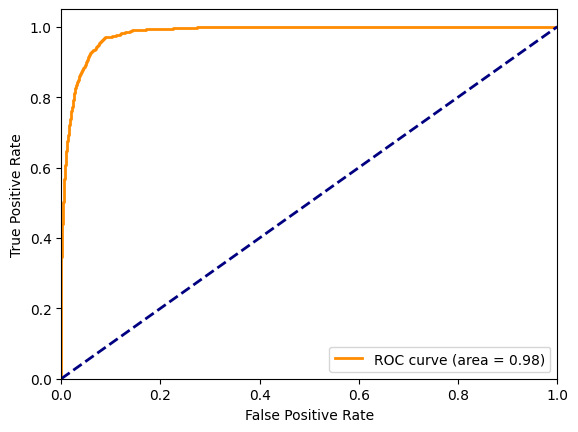

In [926]:
plt.figure()
plt.plot(fpr,tpr,color='darkorange',lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0,1],[0,1],color='navy',lw=2,linestyle='--')
plt.xlim(0.0,1.0)
plt.ylim(0.0,1.05)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

## Model evaluation using rankoreder and ks statistic

In [933]:
probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]

df_eval=pd.DataFrame({
    "Default Truth":y_test,
    'Default Probability':probabilities
})
df_eval.head()

,Default Truth,Default Probability
33553,0,0.00
9427,0,0.76
199,0,0.12
12447,0,0.42
39489,0,0.00


In [934]:
df_eval['Decile'] =pd.qcut(df_eval['Default Probability'],10,labels=False,duplicates='drop')

df_eval.head()

,Default Truth,Default Probability,Decile
33553,0,0.00,1
9427,0,0.76,8
199,0,0.12,7
12447,0,0.42,8
39489,0,0.00,5


In [936]:
df_grouped = df_eval.groupby('Decile').apply(lambda x : pd.Series({
    'Min Prob':x['Default Probability'].min(),
    'Max Prob':x['Default Probability'].max(),
    'Events':x['Default Truth'].sum(),
    'Non-events':x['Default Truth'].count() - x['Default Truth'].sum(),
}))

df_grouped.reset_index(inplace=True)
df_grouped

,Decile,Min Prob,Max Prob,Events,Non-events
0,0,0.00,0.00,0.00,1250.00
1,1,0.00,0.00,0.00,1250.00
2,2,0.00,0.00,0.00,1250.00
3,3,0.00,0.00,0.00,1250.00
4,4,0.00,0.00,0.00,1250.00
5,5,0.00,0.00,1.00,1249.00
6,6,0.00,0.03,2.00,1248.00
7,7,0.03,0.20,16.00,1234.00
8,8,0.20,0.82,172.00,1078.00
9,9,0.82,1.00,917.00,333.00


In [938]:
df_grouped['Event Rate'] = df_grouped['Events']*100/(df_grouped['Events']+df_grouped['Non-events'])
df_grouped['Nin-event Rate'] = df_grouped['Non-events']*100/(df_grouped['Events']+df_grouped['Non-events'])

In [939]:
df_grouped = df_grouped.sort_values(by='Decile',ascending=False).reset_index(drop=True)
df_grouped

,Decile,Min Prob,Max Prob,Events,Non-events,Event Rate,Nin-event Rate
0,9,0.82,1.00,917.00,333.00,73.36,26.64
1,8,0.20,0.82,172.00,1078.00,13.76,86.24
2,7,0.03,0.20,16.00,1234.00,1.28,98.72
3,6,0.00,0.03,2.00,1248.00,0.16,99.84
4,5,0.00,0.00,1.00,1249.00,0.08,99.92
5,4,0.00,0.00,0.00,1250.00,0.00,100.00
6,3,0.00,0.00,0.00,1250.00,0.00,100.00
7,2,0.00,0.00,0.00,1250.00,0.00,100.00
8,1,0.00,0.00,0.00,1250.00,0.00,100.00
9,0,0.00,0.00,0.00,1250.00,0.00,100.00


In [940]:
df_grouped['Cum Events'] = df_grouped['Events'].cumsum()
df_grouped['Cum  Non-events'] = df_grouped['Non-events'].cumsum()
df_grouped

,Decile,Min Prob,Max Prob,Events,Non-events,Event Rate,Nin-event Rate,Cum Events,Cum Non-events
0,9,0.82,1.00,917.00,333.00,73.36,26.64,917.00,333.00
1,8,0.20,0.82,172.00,1078.00,13.76,86.24,1089.00,1411.00
2,7,0.03,0.20,16.00,1234.00,1.28,98.72,1105.00,2645.00
3,6,0.00,0.03,2.00,1248.00,0.16,99.84,1107.00,3893.00
4,5,0.00,0.00,1.00,1249.00,0.08,99.92,1108.00,5142.00
5,4,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,6392.00
6,3,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,7642.00
7,2,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,8892.00
8,1,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,10142.00
9,0,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,11392.00


In [941]:
df_grouped['Cum Events Rate'] = df_grouped['Cum Events'] * 100 / df_grouped['Events'].sum()
df_grouped['Cum Non-events Rate'] = df_grouped['Cum  Non-events'] * 100 / df_grouped['Non-events'].sum()
df_grouped

,Decile,Min Prob,Max Prob,Events,Non-events,Event Rate,Nin-event Rate,Cum Events,Cum Non-events,Cum Events Rate,Cum Non-events Rate
0,9,0.82,1.00,917.00,333.00,73.36,26.64,917.00,333.00,82.76,2.92
1,8,0.20,0.82,172.00,1078.00,13.76,86.24,1089.00,1411.00,98.29,12.39
2,7,0.03,0.20,16.00,1234.00,1.28,98.72,1105.00,2645.00,99.73,23.22
3,6,0.00,0.03,2.00,1248.00,0.16,99.84,1107.00,3893.00,99.91,34.17
4,5,0.00,0.00,1.00,1249.00,0.08,99.92,1108.00,5142.00,100.00,45.14
5,4,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,6392.00,100.00,56.11
6,3,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,7642.00,100.00,67.08
7,2,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,8892.00,100.00,78.05
8,1,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,10142.00,100.00,89.03
9,0,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,11392.00,100.00,100.00


In [942]:
df_grouped['KS'] = abs(df_grouped['Cum Events Rate'] - df_grouped['Cum Non-events Rate'])
df_grouped

,Decile,Min Prob,Max Prob,Events,Non-events,Event Rate,Nin-event Rate,Cum Events,Cum Non-events,Cum Events Rate,Cum Non-events Rate,KS
0,9,0.82,1.00,917.00,333.00,73.36,26.64,917.00,333.00,82.76,2.92,79.84
1,8,0.20,0.82,172.00,1078.00,13.76,86.24,1089.00,1411.00,98.29,12.39,85.90
2,7,0.03,0.20,16.00,1234.00,1.28,98.72,1105.00,2645.00,99.73,23.22,76.51
3,6,0.00,0.03,2.00,1248.00,0.16,99.84,1107.00,3893.00,99.91,34.17,65.74
4,5,0.00,0.00,1.00,1249.00,0.08,99.92,1108.00,5142.00,100.00,45.14,54.86
5,4,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,6392.00,100.00,56.11,43.89
6,3,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,7642.00,100.00,67.08,32.92
7,2,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,8892.00,100.00,78.05,21.95
8,1,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,10142.00,100.00,89.03,10.97
9,0,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,11392.00,100.00,100.00,0.00


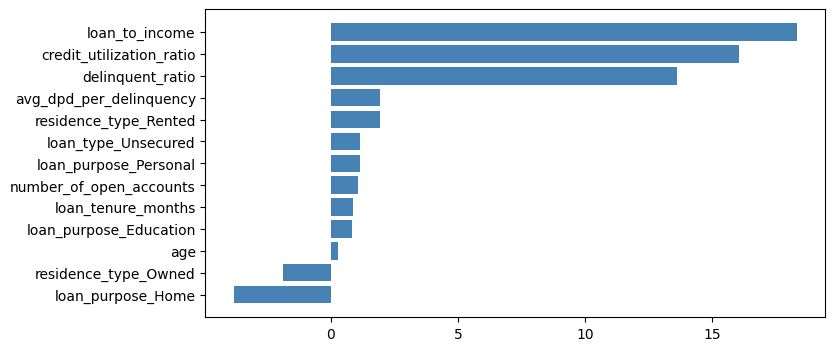

In [943]:
final_model = best_model_logistic

feature_importance = final_model.coef_[0]

coef_df = pd.DataFrame(feature_importance,index=X_test_encoded.columns,columns=['Coefficients'])

coef_df = pd.DataFrame(feature_importance,index=X_test_encoded.columns,columns=['Coefficients'])
coef_df = coef_df.sort_values(by='Coefficients',ascending=True)

plt.figure(figsize=(8,4))

plt.barh(coef_df.index,coef_df['Coefficients'],color='steelblue')

plt.show()

In [945]:
from joblib import dump

model_data = {
    'model':final_model,
    'features':X_test_encoded.columns,
    'scalar':scaler,
    'cols_to_scale':cols_to_scale
}

dump(model_data,'artifacts/model_data.joblib')

['artifacts/model_data.joblib']